# Two groups of dots: averaging or choosing?

Sridhar et al. (2021) showed zebrafish two virtual conspecifics moving back and forth in parallel: while the two are
close the fish swims between them, and beyond a critical separation it follows one of them. No real bout of our data
ever saw two groups, so here the trained models are given two dot groups A and B and one of four rules for combining
them (`twin/joint.py`):

- **effects**: each group's effect on the turn is computed separately and the effects are summed (motor summation);
- **add**: the two groups are pooled into one input (sensory pooling);
- **avg**: the same, normalised (the input is the average of the two);
- **nearest**: only the nearer group is seen (selection).

This notebook shows how the experiment is built, simulates a small version of the thesis maps
(Figure fig:bifurcation, notebook `07_two_groups`) and makes videos of single fish. Everything is simulated here
(about 10 s per separation and 1-2 min per video); nothing needs the stored two-group runs, which are used when they
exist (they are not in the output zip).

<a id="contents"></a>
**Contents**

1. [How the experiment is built](#built)
2. [A small map](#map)
3. [One fish at three separations](#separations)
4. [The four rules side by side](#rules)
5. [M6 against F](#models)

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Video, display

from twin import two_targets as TT

MODEL = "F"        # "F" or "M6"
SEED = 0           # cross-validation seed of the unit: 0 or 101 (never pooled)
PAIR = "4v4"       # dots in A v B: "1v1", "4v4", "1v4", "2v8"
TAG = TT.TAGS[(MODEL, SEED)]
print(f"{MODEL} seed {SEED}: unit {TAG}; videos -> output/experiments/two_dot_groups/")

def show(mp4, width=900):
    """Play a video in the notebook (a link to the file, not embedded: open the notebook locally to play it)."""
    try:
        p = Path(os.path.relpath(mp4)).as_posix()
    except ValueError:                                   # another drive
        p = str(mp4)
    display(Video(p, embed=False, width=width, html_attributes="controls loop muted"))

F seed 0: unit 14f; videos -> output/experiments/two_dot_groups/


<a id="built"></a>
## How the experiment is built

`twin/two_targets.py`, `AnchoredParallelProvider`. The dish has **twice the training radius** (98 mm), so the tracks
fit up to L = 100 mm; every wall mechanism of the model scales with the radius, so the fish senses the training dish
magnified. Each simulated fish swims 10 blocks: 100 s lead-in, then 60 s with the two groups and 50 s pause, as in
the rig. In each block:

- at the fish's **first bout** of the block the pair is placed 20 mm ahead of it, the fish exactly on the midline
  (equidistant from A and B), the track axis pointing from the fish toward the dish centre (± 30°);
- both group centroids move back and forth along two parallel tracks (half-length 20 mm, 2 mm/s, in step), at
  lateral separation L; A alternates sides between blocks;
- the model sees each group as its centroid, count and moving flag; the rule combines them.

The readout is the fish's **lateral position** (+ = toward A) at the bouts **behind the pair** (the rule of
Sridhar et al.) 20-60 s after the onset: near 0 the fish is between the groups, near ± L/2 it is on one of them.
Below, fish 0 of the run at L = 50 mm, its first two blocks.

[↑ back to contents](#contents)

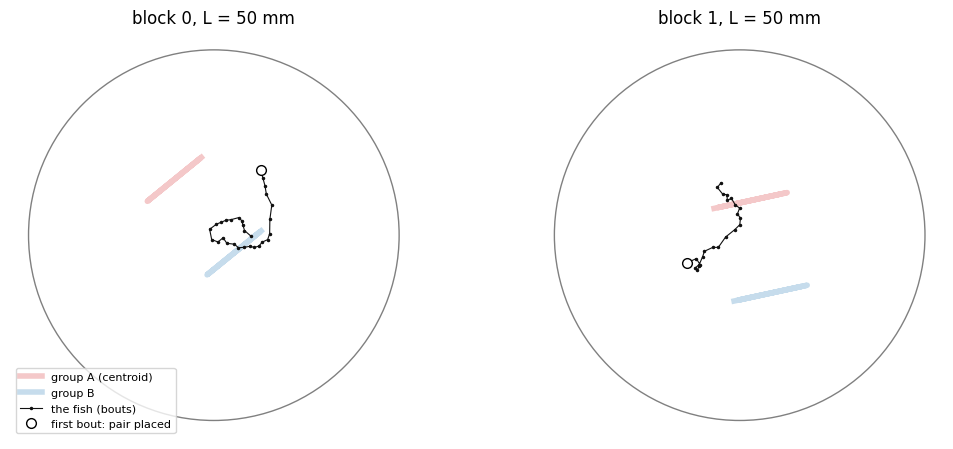

In [2]:
L = 50.0
g, prov, dish = TT.rerun(TAG, PAIR, L, k=0)
t, x, y = (np.asarray(g[k], float) for k in ("t_onset_s", "x_px", "y_px"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for j, ax in enumerate(axes):
    t0 = (prov.lead_f + j * prov.cyc_f) / prov.fps
    m = (t >= t0) & (t < t0 + TT.STIM_S)
    tb = t[m] - t0
    tracks = [prov._state(j, int(round(max(s, prov.anchor[j][2]) * prov.fps))) for s in tb]
    A = np.array([q[0][0] for q in tracks]); B = np.array([q[0][1] for q in tracks])
    cx, cy, R = dish
    ax.add_patch(plt.Circle((cx, cy), R, fill=False, color="0.5"))
    ax.plot(A[:, 0], A[:, 1], color=TT.COL_A, lw=4, alpha=0.25, label="group A (centroid)")
    ax.plot(B[:, 0], B[:, 1], color=TT.COL_B, lw=4, alpha=0.25, label="group B")
    ax.plot(x[m], y[m], ".-", color=TT.COL_FISH, ms=3, lw=0.8, label="the fish (bouts)")
    ax.plot(x[m][0], y[m][0], "o", color="k", ms=7, mfc="w", label="first bout: pair placed")
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_title(f"block {j}, L = {L:g} mm"); ax.axis("off")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

<a id="map"></a>
## A small map

The thesis map at six separations instead of 41: 15 fish (3 per fold model) x 10 blocks per separation, the lateral
position of the bouts behind the pair, 20-60 s after the onset, each column normalised to its maximum (dashed: the two
tracks). About 10 s per separation (simulated unless the stored run exists). Under **effects** the fish stays between
the groups while they are close and splits onto one of them once they are about 50-60 mm apart (F; M6 later); under
**nearest** it splits as soon as the groups can be told apart.

[↑ back to contents](#contents)

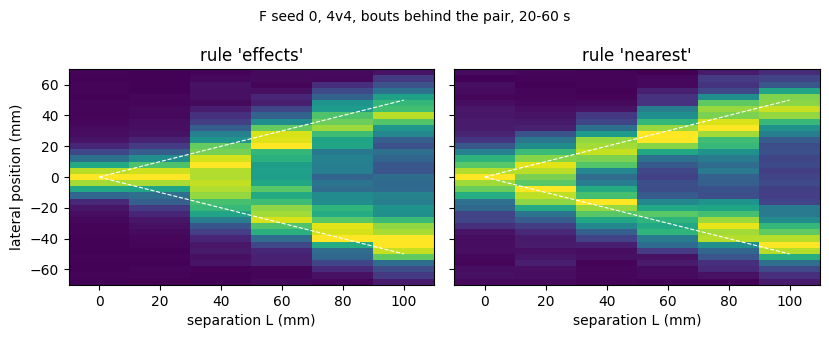

In [3]:
Ls = (0.0, 20.0, 40.0, 60.0, 80.0, 100.0)
RULES = ("effects", "nearest")
edges = np.arange(-70, 74, 4.0)
fig, axes = plt.subplots(1, len(RULES), figsize=(4.2 * len(RULES), 3.4), sharey=True)
for ax, rule in zip(axes, RULES):
    Z = []
    for L in Ls:
        b = TT.report_runs(TAG, PAIR, L, rule)
        b = b[b.groupby(["fish", "blk"]).cumcount() > 0]          # the anchoring bout sits at 0 by construction
        h, _ = np.histogram(b[(b.t_blk >= 20) & (b.along_mm <= 0)].lat_mm, bins=edges)
        Z.append(h / max(h.max(), 1))
    xe = np.r_[np.array(Ls) - 10, Ls[-1] + 10]
    ax.pcolormesh(xe, edges, np.array(Z).T, cmap="viridis", vmin=0, vmax=1)
    ax.plot(Ls, np.array(Ls) / 2, "w--", lw=0.8); ax.plot(Ls, -np.array(Ls) / 2, "w--", lw=0.8)
    ax.set(title=f"rule '{rule}'", xlabel="separation L (mm)")
axes[0].set_ylabel("lateral position (mm)")
fig.suptitle(f"{MODEL} seed {SEED}, {PAIR}, bouts behind the pair, 20-60 s", fontsize=10)
plt.tight_layout(); plt.show()

<a id="separations"></a>
## One fish at three separations

The same fish and block at L = 20, 50 and 80 mm (the equidistant start of the thesis maps). The fish and block are
**chosen** to show the pattern (`TT.pick`: closest to the midline at 20 mm and to one track at 80 mm, among the 150
trials), so this is an illustration, not a typical trial; the maps above are the result. Below each dish its lateral
position over the block, with the two tracks at ± L/2.

**What to watch.** At 20 mm the fish swims between the two groups (lateral near 0); at 80 mm it commits to one and
follows it. What fails: the fish follows the groups' positions, not their motion; it does not swim along with them as
a real fish follows a conspecific (the alignment the shoaling notebook comes back to).

[↑ back to contents](#contents)

In [4]:
mp4, (k, j) = TT.video(TAG, Ls=(20.0, 50.0, 80.0), pair=PAIR)
print(f"fish {k}, block {j}: {mp4.name}")
show(mp4)

fish 12, block 6: 4v4_14f_effects_L20-50-80.mp4


<a id="rules"></a>
## The four rules side by side

The same fish and block at L = 80 mm under each rule. Under **effects** the fish commits to one group; **add** and
**avg** pool the two groups into one input whose centroid lies between them, so the fish hardly splits; **nearest**
follows one group as closely as a fish shown only that group.

[↑ back to contents](#contents)

In [5]:
mp4, (k, j) = TT.rules_video(TAG, L=80.0, pair=PAIR)
print(f"fish {k}, block {j}: {mp4.name}")
show(mp4)

fish 12, block 6: 4v4_14f_rules_L80.mp4


<a id="models"></a>
## M6 against F

The other model at the same seed, its own chosen fish and block. In the thesis maps F switches at about 50 mm and M6
at about 90 mm, leaving more of the midline occupied: at 50 mm, M6 more often still swims between the groups.

[↑ back to contents](#contents)

In [6]:
OTHER = "M6" if MODEL == "F" else "F"
mp4, (k, j) = TT.video(TT.TAGS[(OTHER, SEED)], Ls=(20.0, 50.0, 80.0), pair=PAIR)
print(f"{OTHER} seed {SEED}, fish {k}, block {j}: {mp4.name}")
show(mp4)

M6 seed 0, fish 10, block 7: 4v4_26e_effects_L20-50-80.mp4
